# Markov vs Shapley, side by side, on GA4 ecommerce journeys

`CompareAttribution` fits both static models on the same journeys and
returns aligned tables. The two methods answer different statistical
questions — removal effects on the full path chain versus marginal
contributions over channel coalitions — and can disagree materially
without either being defective.

In [1]:
# In Colab, install the package first:
# %pip install "do-attribution[viz,temporal]"
%matplotlib inline
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="Sum of Shapley values")
warnings.filterwarnings("ignore", message="Total removal effect is 0")
pd.set_option("display.width", 160)

IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

## Load and summarize the GA4 journeys

In [2]:
journeys = pd.read_csv("ga4_attribution_journeys.csv")

required = {"path", "conversion", "anchor_timestamp"}
assert required.issubset(journeys.columns), f"missing columns: {required - set(journeys.columns)}"
assert journeys["path"].notna().all() and (journeys["path"].str.len() > 0).all()
assert journeys["conversion"].isin([0, 1]).all()

paths = journeys["path"]
conversions = journeys["conversion"]
timestamps = pd.to_datetime(journeys["anchor_timestamp"]).dt.tz_localize(None)

channels = sorted({channel for path in paths for channel in path.split(" > ")})
path_lengths = paths.str.count(" > ") + 1
print(f"journeys        : {len(journeys):,}")
print(f"conversions     : {conversions.sum():,}  (rate {conversions.mean():.4f})")
print(f"date range      : {timestamps.min().date()} to {timestamps.max().date()}")
print(f"channels ({len(channels)})    : {', '.join(channels)}")
print(f"path length     : mean {path_lengths.mean():.2f}, max {path_lengths.max()}; "
      f"{(path_lengths > 1).mean():.1%} of journeys are multi-touch")
journeys.head()

journeys        : 272,792
conversions     : 4,848  (rate 0.0178)
date range      : 2020-11-01 to 2021-01-31
channels (8)    : Affiliate, Direct, Email, Organic Search, Organic Social, Other, Paid Search, Referral
path length     : mean 1.17, max 12; 11.4% of journeys are multi-touch


,journey_id,path,conversion,journey_start,anchor_timestamp,session_count,touch_count,purchase_count
0,journey_0000001,Organic Search,0,2020-12-12T04:11:17Z,2020-12-12T04:11:17Z,1,1,0
1,journey_0000002,Direct,0,2021-01-07T18:35:34Z,2021-01-07T18:35:34Z,1,1,0
2,journey_0000003,Direct,0,2021-01-20T11:04:59Z,2021-01-20T11:04:59Z,1,1,0
3,journey_0000004,Other > Referral,0,2020-11-04T09:21:11Z,2020-11-04T13:43:30Z,2,2,0
4,journey_0000005,Organic Search,0,2020-12-11T17:25:12Z,2020-12-11T17:25:12Z,1,1,0


## Fit both models through `CompareAttribution`

In [3]:
from do_attribution import CompareAttribution

comparison = CompareAttribution(markov_removal_strategy="redirect_to_null")
comparison_results = comparison.fit(paths, conversions)
aligned = comparison.attribution_frame()
display(aligned.round(4))
print("Unavailable normalized models:", comparison.unavailable_models())

,markov,shapley
Affiliate,0.0019,0.0003
Direct,0.1077,0.0986
Email,0.0040,0.0040
Organic Search,0.3621,0.3854
Organic Social,0.0012,0.0009
Other,0.0801,0.0668
Paid Search,0.0140,0.0133
Referral,0.4290,0.4307


Unavailable normalized models: {}


## Model differences

In [4]:
differences = comparison.difference_frame("markov")
display(differences.round(4))
available_differences = differences.dropna(axis=1, how="all")
if available_differences.empty:
    print("Normalized differences are unavailable because Shapley normalization was refused.")
    raw_shapley = pd.Series(
        comparison_results["shapley"]["shapley_values"],
        name="raw_shapley_value",
    )
    display(raw_shapley.sort_values(ascending=False).round(4).to_frame())
else:
    largest_model = available_differences.abs().max().idxmax()
    largest_channel = available_differences[largest_model].abs().idxmax()
    print("Largest disagreement:", largest_model, "on", largest_channel)

,shapley_minus_markov
Affiliate,-0.0017
Direct,-0.0091
Email,-0.0001
Organic Search,0.0233
Organic Social,-0.0003
Other,-0.0132
Paid Search,-0.0007
Referral,0.0017


Largest disagreement: shapley_minus_markov on Organic Search


For these journeys both models produce a valid normalized attribution vector,
so every channel has a Markov share, a Shapley share, and a difference. Both
models put Referral first and Organic Search second, and no channel's share
differs by more than about 2.3 percentage points. The differences column shows
where removal effects on the path chain and equal splitting within channel
coalitions allocate credit differently.

## Comparison plot

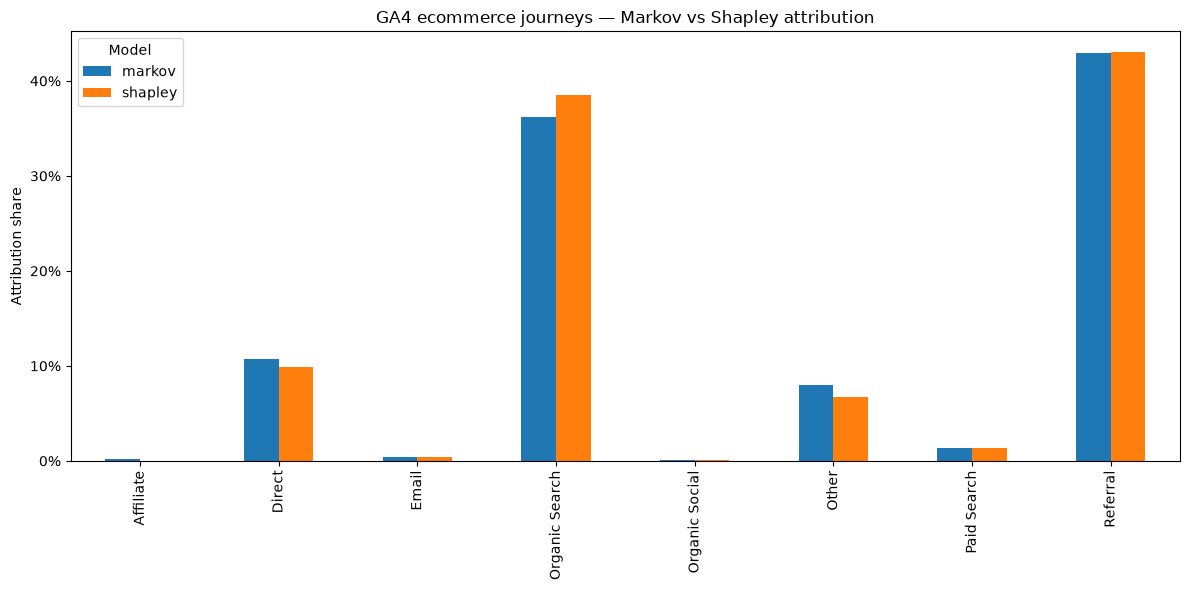

In [5]:
from do_attribution.visualization import plot_attribution_comparison

available_attribution = aligned.dropna(axis=1, how="all")
fig = plot_attribution_comparison(
    available_attribution,
    title="GA4 ecommerce journeys — Markov vs Shapley attribution",
)
fig.savefig(IMAGES / "ga4_model_comparison.png", dpi=110, bbox_inches="tight")
plt.show()